# Data Collection and Cleaning

**Loading Dataset Using Pandas**

In [220]:
import pandas as pd
import numpy as np

df=pd.read_csv('https://archive.ics.uci.edu/static/public/352/data.csv')


**Identifying Missing Values and Duplicate Transactions**

In [221]:
dframe=df

In [222]:
print(dframe.isna().sum())
print()
print('Total missing: ',dframe.isna().sum().sum())

InvoiceNo           0
StockCode           0
Description      1454
Quantity            0
InvoiceDate         0
UnitPrice           0
CustomerID     135080
Country             0
dtype: int64

Total missing:  136534


In [223]:
dframe[dframe.duplicated()]

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
517,536409,21866,UNION JACK FLAG LUGGAGE TAG,1,12/1/2010 11:45,1.25,17908.0,United Kingdom
527,536409,22866,HAND WARMER SCOTTY DOG DESIGN,1,12/1/2010 11:45,2.10,17908.0,United Kingdom
537,536409,22900,SET 2 TEA TOWELS I LOVE LONDON,1,12/1/2010 11:45,2.95,17908.0,United Kingdom
539,536409,22111,SCOTTIE DOG HOT WATER BOTTLE,1,12/1/2010 11:45,4.95,17908.0,United Kingdom
555,536412,22327,ROUND SNACK BOXES SET OF 4 SKULLS,1,12/1/2010 11:49,2.95,17920.0,United Kingdom
...,...,...,...,...,...,...,...,...
541675,581538,22068,BLACK PIRATE TREASURE CHEST,1,12/9/2011 11:34,0.39,14446.0,United Kingdom
541689,581538,23318,BOX OF 6 MINI VINTAGE CRACKERS,1,12/9/2011 11:34,2.49,14446.0,United Kingdom
541692,581538,22992,REVOLVER WOODEN RULER,1,12/9/2011 11:34,1.95,14446.0,United Kingdom
541699,581538,22694,WICKER STAR,1,12/9/2011 11:34,2.10,14446.0,United Kingdom


In [224]:
dframe=dframe.drop_duplicates()
dframe[dframe.duplicated()]

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country


In [225]:
dframe.count()

InvoiceNo      536641
StockCode      536641
Description    535187
Quantity       536641
InvoiceDate    536641
UnitPrice      536641
CustomerID     401604
Country        536641
dtype: int64

In [226]:
dfnull=dframe

In [227]:
print(dfnull.isna().sum())
print()
print('Total missing: ',dfnull.isna().sum().sum())

InvoiceNo           0
StockCode           0
Description      1454
Quantity            0
InvoiceDate         0
UnitPrice           0
CustomerID     135037
Country             0
dtype: int64

Total missing:  136491


In [228]:
dfnull[dfnull['CustomerID'].isnull()]

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
622,536414,22139,NaN,56,12/1/2010 11:52,0.00,NaN,United Kingdom
1443,536544,21773,DECORATIVE ROSE BATHROOM BOTTLE,1,12/1/2010 14:32,2.51,NaN,United Kingdom
1444,536544,21774,DECORATIVE CATS BATHROOM BOTTLE,2,12/1/2010 14:32,2.51,NaN,United Kingdom
1445,536544,21786,POLKADOT RAIN HAT,4,12/1/2010 14:32,0.85,NaN,United Kingdom
1446,536544,21787,RAIN PONCHO RETROSPOT,2,12/1/2010 14:32,1.66,NaN,United Kingdom
...,...,...,...,...,...,...,...,...
541536,581498,85099B,JUMBO BAG RED RETROSPOT,5,12/9/2011 10:26,4.13,NaN,United Kingdom
541537,581498,85099C,JUMBO BAG BAROQUE BLACK WHITE,4,12/9/2011 10:26,4.13,NaN,United Kingdom
541538,581498,85150,LADIES & GENTLEMEN METAL SIGN,1,12/9/2011 10:26,4.96,NaN,United Kingdom
541539,581498,85174,S/4 CACTI CANDLES,1,12/9/2011 10:26,10.79,NaN,United Kingdom


In [229]:
dfnull[dfnull['Description'].isnull()]

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
622,536414,22139,NaN,56,12/1/2010 11:52,0.0,NaN,United Kingdom
1970,536545,21134,NaN,1,12/1/2010 14:32,0.0,NaN,United Kingdom
1971,536546,22145,NaN,1,12/1/2010 14:33,0.0,NaN,United Kingdom
1972,536547,37509,NaN,1,12/1/2010 14:33,0.0,NaN,United Kingdom
1987,536549,85226A,NaN,1,12/1/2010 14:34,0.0,NaN,United Kingdom
...,...,...,...,...,...,...,...,...
535322,581199,84581,NaN,-2,12/7/2011 18:26,0.0,NaN,United Kingdom
535326,581203,23406,NaN,15,12/7/2011 18:31,0.0,NaN,United Kingdom
535332,581209,21620,NaN,6,12/7/2011 18:35,0.0,NaN,United Kingdom
536981,581234,72817,NaN,27,12/8/2011 10:33,0.0,NaN,United Kingdom


In [230]:
dfnull=dfnull.dropna(subset=['Description'])
dfnull.count()

InvoiceNo      535187
StockCode      535187
Description    535187
Quantity       535187
InvoiceDate    535187
UnitPrice      535187
CustomerID     401604
Country        535187
dtype: int64

**Handling Cancellations**

In [231]:
cancellations=dfnull[dfnull['InvoiceNo'].astype(str).str.startswith('C')]
cancellations

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
141,C536379,D,Discount,-1,12/1/2010 9:41,27.50,14527.0,United Kingdom
154,C536383,35004C,SET OF 3 COLOURED FLYING DUCKS,-1,12/1/2010 9:49,4.65,15311.0,United Kingdom
235,C536391,22556,PLASTERS IN TIN CIRCUS PARADE,-12,12/1/2010 10:24,1.65,17548.0,United Kingdom
236,C536391,21984,PACK OF 12 PINK PAISLEY TISSUES,-24,12/1/2010 10:24,0.29,17548.0,United Kingdom
237,C536391,21983,PACK OF 12 BLUE PAISLEY TISSUES,-24,12/1/2010 10:24,0.29,17548.0,United Kingdom
...,...,...,...,...,...,...,...,...
540449,C581490,23144,ZINC T-LIGHT HOLDER STARS SMALL,-11,12/9/2011 9:57,0.83,14397.0,United Kingdom
541541,C581499,M,Manual,-1,12/9/2011 10:28,224.69,15498.0,United Kingdom
541715,C581568,21258,VICTORIAN SEWING BOX LARGE,-5,12/9/2011 11:57,10.95,15311.0,United Kingdom
541716,C581569,84978,HANGING HEART JAR T-LIGHT HOLDER,-1,12/9/2011 11:58,1.25,17315.0,United Kingdom


**dfnull** *is the cleaned dataset.*

# Exploratory Data Analysis

In [232]:
import matplotlib.pyplot as plt
import seaborn as sns

In [233]:
dfnull.describe()

,Quantity,UnitPrice,CustomerID
count,535187.000000,535187.000000,401604.000000
mean,9.671593,4.645242,15281.160818
std,219.059056,97.364810,1714.006089
min,-80995.000000,-11062.060000,12346.000000
25%,1.000000,1.250000,13939.000000
50%,3.000000,2.080000,15145.000000
75%,10.000000,4.130000,16784.000000
max,80995.000000,38970.000000,18287.000000


In [234]:
# Removing negative data from Quantity and UnitPrice
numdf=dfnull.select_dtypes(include=[np.number])
negative_counts= (numdf<0).sum()
print("Columns with negative counts: ")
print(negative_counts)

Columns with negative counts: 
Quantity      9725
UnitPrice        2
CustomerID       0
dtype: int64


In [235]:
dfnull=dfnull[dfnull['Quantity']>0]
dfnull=dfnull[dfnull['UnitPrice']>0]
print("Remaining row counts:")
dfnull.count()

Remaining row counts:


InvoiceNo      524878
StockCode      524878
Description    524878
Quantity       524878
InvoiceDate    524878
UnitPrice      524878
CustomerID     392692
Country        524878
dtype: int64

In [236]:
#Converting Invoicedate to datetime format
dfnull['InvoiceDate']=pd.to_datetime(dfnull['InvoiceDate'])

#Deriving month from invoicedate
dfnull['Month']=dfnull['InvoiceDate'].dt.month

#Calculating sales
dfnull['Sales']=dfnull['UnitPrice']*dfnull['Quantity']
print("dataframe with new column:")
dfnull.head()

dataframe with new column:


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country,Month,Sales
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850.0,United Kingdom,12,15.30
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom,12,20.34
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850.0,United Kingdom,12,22.00
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom,12,20.34
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom,12,20.34


**Monthly Revenue**

In [237]:
Monthly_Revenue=dfnull.groupby('Month')['Sales'].sum()
print(Monthly_Revenue)

Month
1      689811.610
2      522545.560
3      716215.260
4      536968.491
5      769296.610
6      760547.010
7      718076.121
8      757841.380
9     1056435.192
10    1151263.730
11    1503866.780
12    1459243.060
Name: Sales, dtype: float64


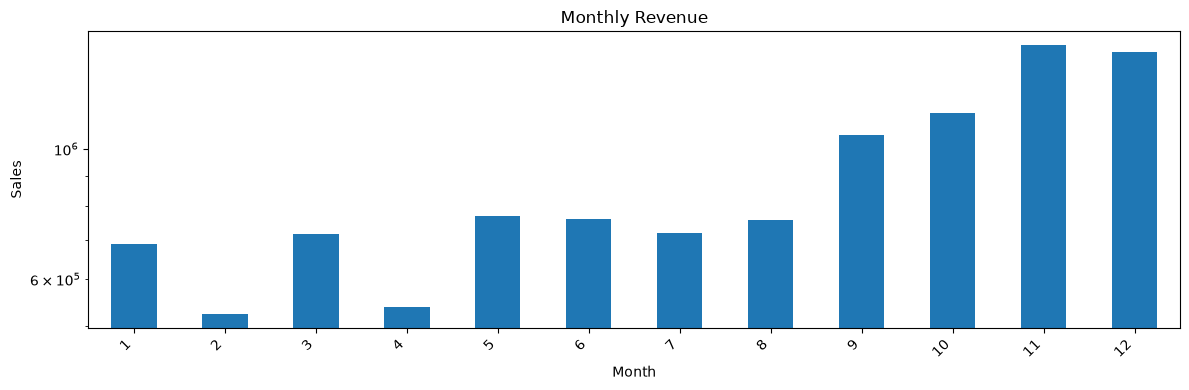

In [238]:
plt.figure(figsize=(12,4))
Monthly_Revenue.plot(kind='bar', logy=True)
plt.title("Monthly Revenue")
plt.xlabel("Month")
plt.ylabel("Sales")
plt.xticks(rotation=45,ha='right')
plt.tight_layout()
plt.show()

**Revenue by Country**

In [239]:
Country_Revenue=dfnull.groupby('Country')['Sales'].sum().sort_values(ascending=False)
print(Country_Revenue)

Country
United Kingdom          9001744.094
Netherlands              285446.340
EIRE                     283140.520
Germany                  228678.400
France                   209625.370
Australia                138453.810
Spain                     61558.560
Switzerland               57067.600
Belgium                   41196.340
Sweden                    38367.830
Japan                     37416.370
Norway                    36165.440
Portugal                  33683.050
Finland                   22546.080
Singapore                 21279.290
Channel Islands           20440.540
Denmark                   18955.340
Italy                     17483.240
Hong Kong                 15483.000
Cyprus                    13502.850
Austria                   10198.680
Israel                     8129.410
Poland                     7334.650
Greece                     4760.520
Unspecified                4740.940
Iceland                    4310.000
Canada                     3666.380
USA                 

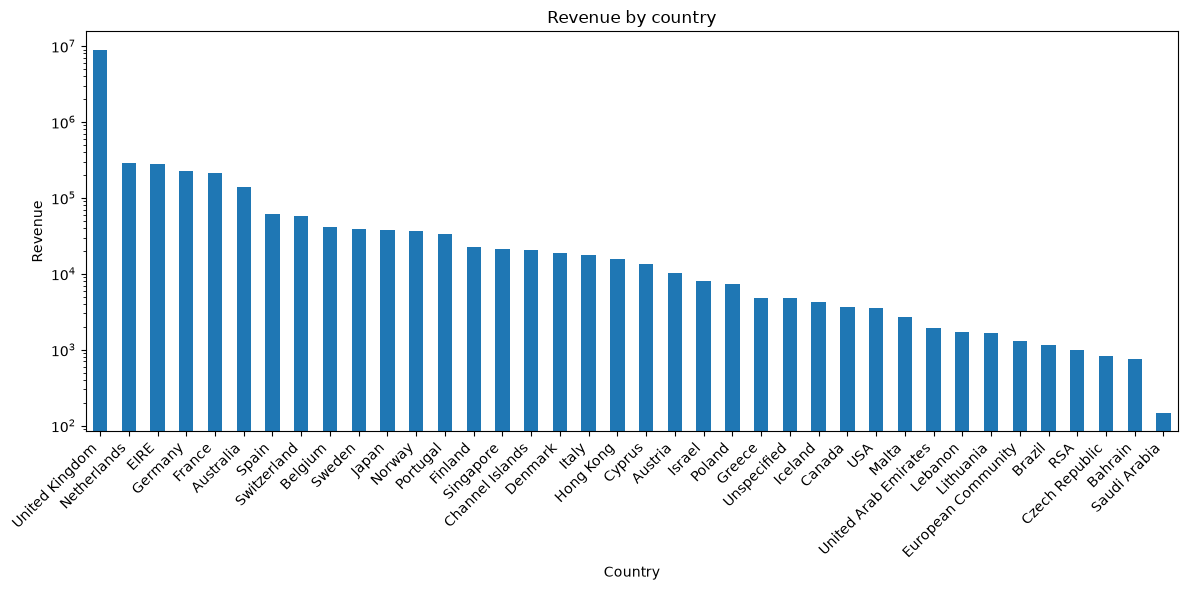

In [240]:
plt.figure(figsize=(12,6))
Country_Revenue.plot(kind='bar', logy=True)
plt.title("Revenue by country")
plt.xlabel("Country")
plt.ylabel("Revenue")
plt.xticks(rotation=45,ha='right')
plt.tight_layout()
plt.show()

**Top Selling Products**

In [241]:
Product_Sales=dfnull.groupby('Description')['Sales'].sum().nlargest(30).sort_values(ascending=False)
Product_Sales

Description
DOTCOM POSTAGE                        206248.77
REGENCY CAKESTAND 3 TIER              174156.54
PAPER CRAFT , LITTLE BIRDIE           168469.60
WHITE HANGING HEART T-LIGHT HOLDER    106236.72
PARTY BUNTING                          99445.23
JUMBO BAG RED RETROSPOT                94159.81
MEDIUM CERAMIC TOP STORAGE JAR         81700.92
POSTAGE                                78101.88
Manual                                 77752.82
RABBIT NIGHT LIGHT                     66870.03
PAPER CHAIN KIT 50'S CHRISTMAS         64875.59
ASSORTED COLOUR BIRD ORNAMENT          58927.62
CHILLI LIGHTS                          54096.36
SPOTTY BUNTING                         42513.48
JUMBO BAG PINK POLKADOT                42401.01
BLACK RECORD COVER FRAME               40633.38
PICNIC BASKET WICKER 60 PIECES         39619.50
DOORMAT KEEP CALM AND COME IN          38133.64
SET OF 3 CAKE TINS PANTRY DESIGN       38108.89
JAM MAKING SET WITH JARS               37082.13
WOOD BLACK BOARD ANT WHITE F

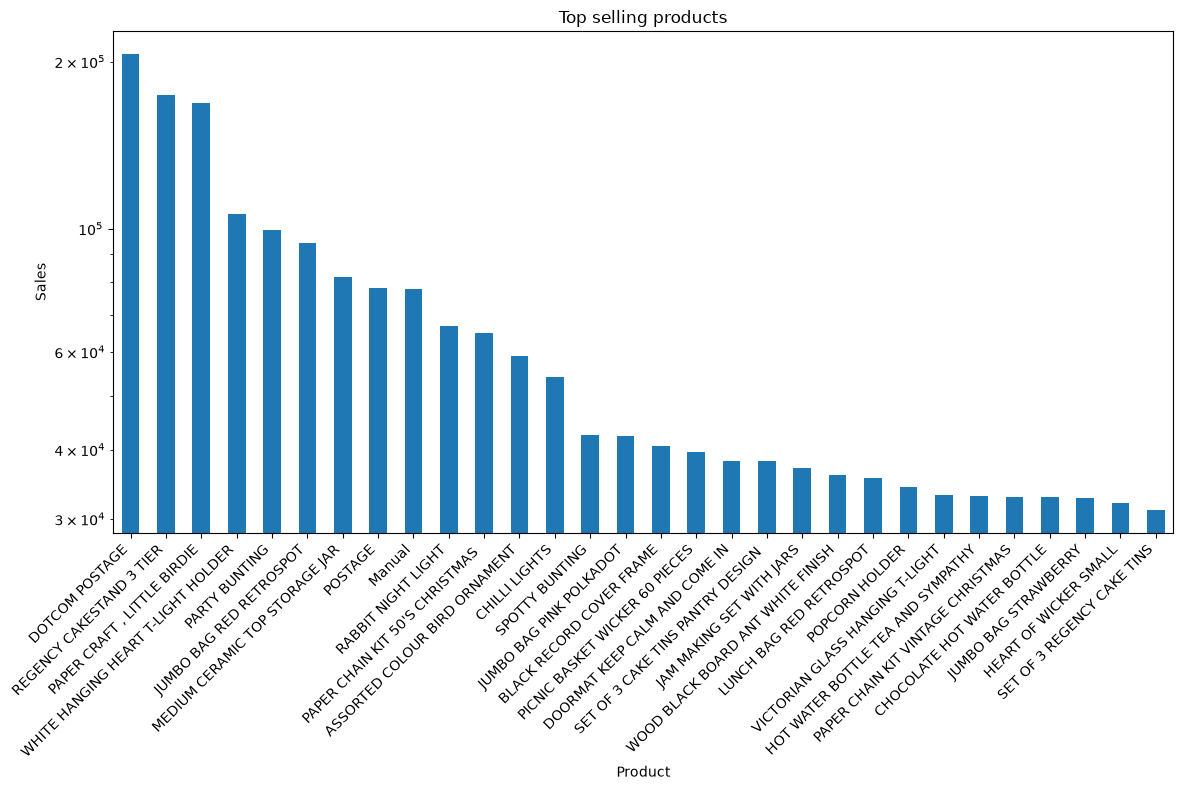

In [242]:
plt.figure(figsize=(12,8))
Product_Sales.plot(kind='bar', logy=True)
plt.title("Top selling products")
plt.xlabel("Product")
plt.ylabel("Sales")
plt.xticks(rotation=45,ha='right')
plt.tight_layout()
plt.show()

**Purchase Frequency**

In [243]:
dfnull['Hour']=dfnull['InvoiceDate'].dt.hour
dfnull['Week']=dfnull['InvoiceDate'].dt.dayofweek
dfnull['Month']=dfnull['InvoiceDate'].dt.month
dfnull['Year']=dfnull['InvoiceDate'].dt.year
hourly_orders=dfnull.groupby('Hour')['StockCode'].count()
weekly_orders=dfnull.groupby('Week')['StockCode'].count()
monthly_orders=dfnull.groupby('Month')['StockCode'].count()
yearly_orders=dfnull.groupby('Year')['StockCode'].count()

print(hourly_orders)
print()
print(weekly_orders)
print()
print(monthly_orders)
print()
print(yearly_orders)

Hour
6         1
7       379
8      8797
9     33684
10    47597
11    55420
12    75986
13    69993
14    65057
15    75665
16    52992
17    27426
18     7676
19     3427
20      778
Name: StockCode, dtype: int64

Week
0     92466
1     98726
2     91467
3    100213
4     79667
6     62339
Name: StockCode, dtype: int64

Month
1     34060
2     26882
3     35497
4     28882
5     35917
6     35716
7     38395
8     34264
9     48900
10    58537
11    82004
12    65824
Name: StockCode, dtype: int64

Year
2010     40991
2011    483887
Name: StockCode, dtype: int64


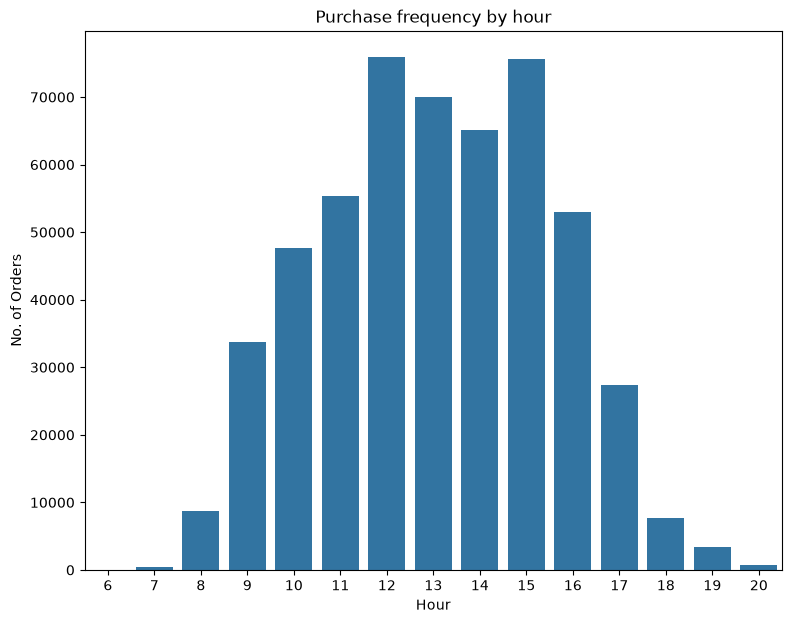

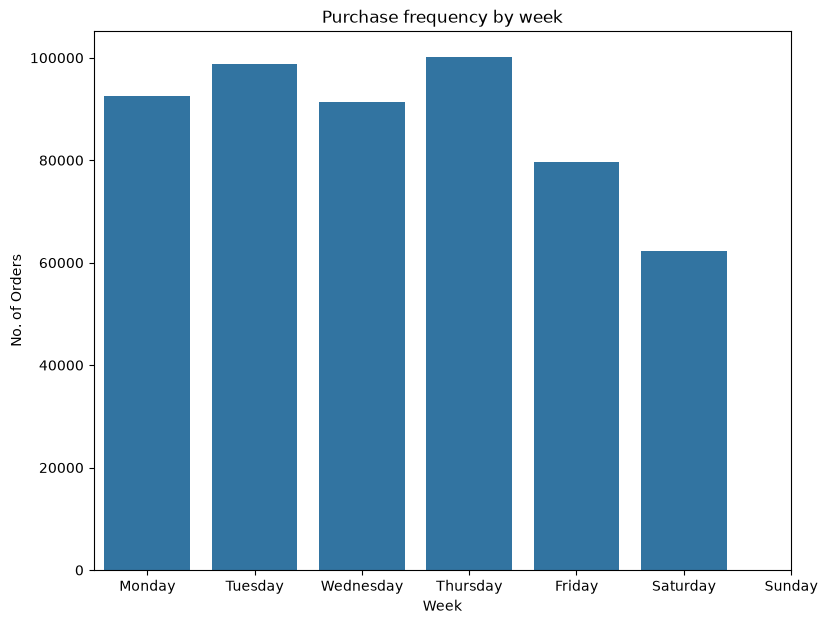

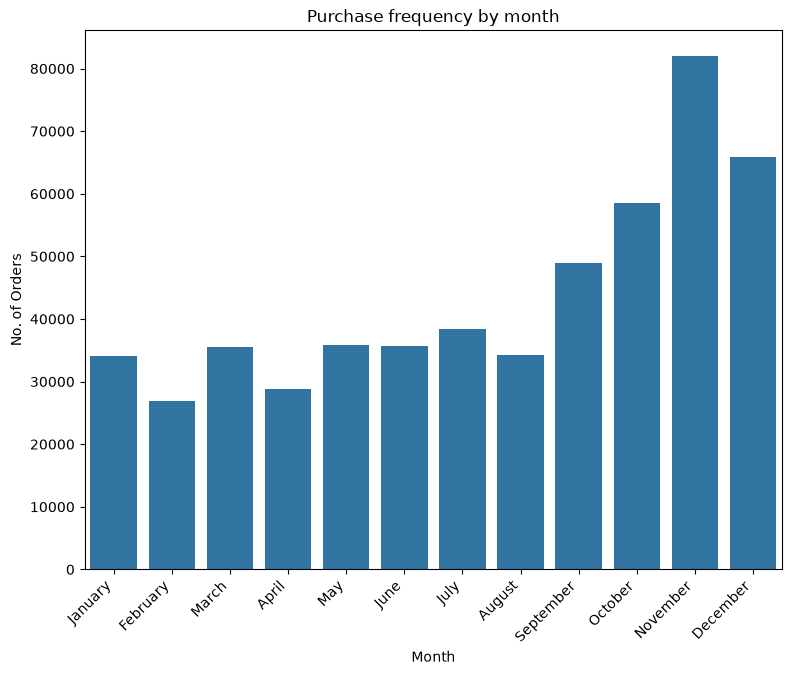

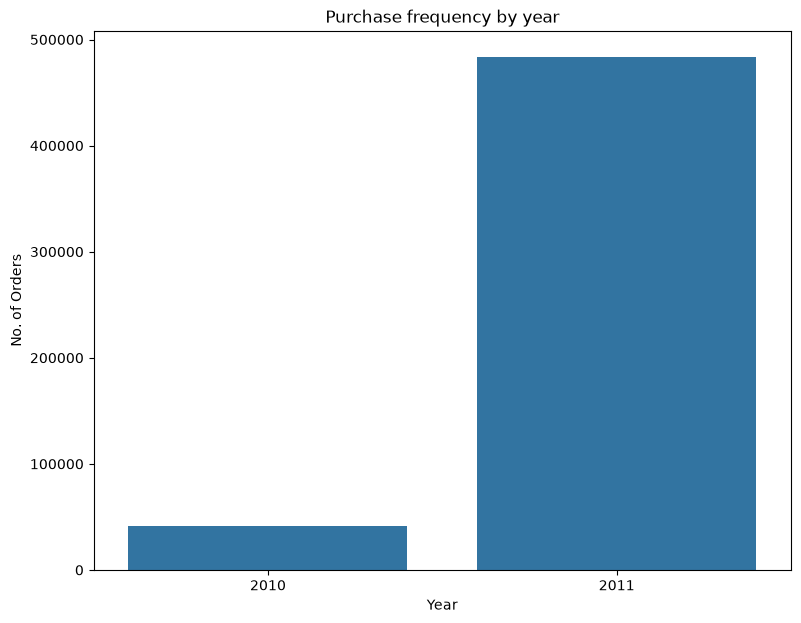

In [244]:
plt.figure(figsize=(9,7))
sns.barplot(x=hourly_orders.index , y=hourly_orders.values, legend=False)
plt.title("Purchase frequency by hour")
plt.xlabel("Hour")
plt.ylabel("No. of Orders")
plt.xticks(ticks=range(15),labels=['6','7','8','9','10','11','12','13','14','15','16','17','18','19','20'])
plt.show()

plt.figure(figsize=(9,7))
sns.barplot(x=weekly_orders.index, y=weekly_orders.values,legend=False)
plt.title("Purchase frequency by week")
plt.xlabel("Week")
plt.ylabel("No. of Orders")
plt.xticks(ticks=range(7),labels=['Monday','Tuesday','Wednesday','Thursday','Friday','Saturday','Sunday'])
plt.show()

plt.figure(figsize=(9,7))
sns.barplot(x=monthly_orders.index, y=monthly_orders.values,legend=False)
plt.title("Purchase frequency by month")
plt.xlabel("Month")
plt.ylabel("No. of Orders")
plt.xticks(rotation=45,ha='right',ticks=range(12),labels=['January','February','March','April','May','June','July','August','September','October','November','December'])
plt.show()
    
plt.figure(figsize=(9,7))
sns.barplot(x=yearly_orders.index, y=yearly_orders.values,legend=False)
plt.title("Purchase frequency by year")
plt.xlabel("Year")
plt.ylabel("No. of Orders")
plt.xticks(ticks=range(2),labels=['2010','2011'])
plt.show()

# Customer Segmentation

**Recency Calculation**

In [245]:
rfm=dfnull

In [246]:
min_date=min(rfm['InvoiceDate'])
max_date=max(rfm['InvoiceDate'])
display("Max date is: "+str(max_date))
display("Min date is: "+str(min_date))

'Max date is: 2011-12-09 12:50:00'

'Min date is: 2010-12-01 08:26:00'

count    4338.000000
mean       92.059474
std       100.012264
min         0.000000
25%        17.000000
50%        50.000000
75%       141.750000
max       373.000000
Name: Recency, dtype: float64

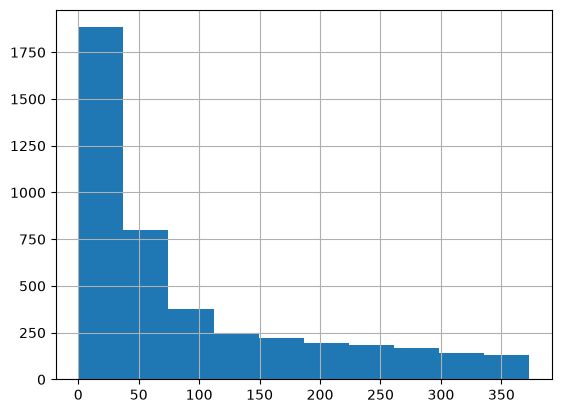

In [247]:
recency_df=rfm.groupby(by='CustomerID',as_index=False)['InvoiceDate'].max()
recency_df["Recency"]=max_date-recency_df['InvoiceDate']
recency_df.rename(columns={'InvoiceDate':'Last_Purchase_Date'},inplace=True)
recency_df['Recency']=recency_df['Recency'].dt.round('D')
recency_df['Recency']=recency_df['Recency']/pd.to_timedelta(1,unit='D')
recency_df['Recency'].hist()
recency_df['Recency'].describe()

**Frequency Calculation**

count    4338.000000
mean        4.272015
std         7.697998
min         1.000000
25%         1.000000
50%         2.000000
75%         5.000000
max       209.000000
Name: Frequency, dtype: float64

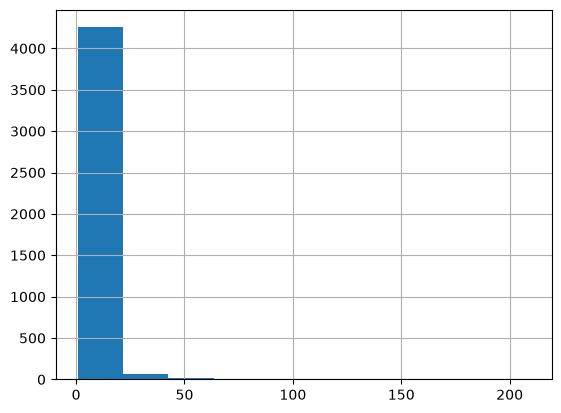

In [248]:
frequency_df=rfm.groupby(['CustomerID']).agg({'InvoiceNo':'nunique'}).reset_index()
frequency_df.sort_values('InvoiceNo',ascending=[False])
frequency_df.rename(columns={'InvoiceNo':'Frequency'},inplace=True)
frequency_df['Frequency'].hist()
frequency_df['Frequency'].describe()

In [249]:
frequency_df['Frequency'].value_counts()

Frequency
1      1493
2       835
3       508
4       388
5       242
6       172
7       143
8        98
9        68
10       54
11       52
12       45
13       30
15       28
14       20
17       18
18       14
20       12
19       12
21       11
16       11
25        8
26        7
28        6
22        5
23        5
30        4
32        3
31        3
37        3
24        3
27        3
34        3
38        2
33        2
55        2
47        2
39        2
209       1
86        1
97        1
35        1
62        1
50        1
57        1
44        1
93        1
73        1
201       1
48        1
41        1
91        1
63        1
51        1
29        1
46        1
124       1
45        1
60        1
Name: count, dtype: int64

**Monetary Calculation**

,CustomerID,MonetaryValue
count,4338.000000,4338.000000
mean,15300.408022,2048.688081
std,1721.808492,8985.230220
min,12346.000000,3.750000
25%,13813.250000,306.482500
50%,15299.500000,668.570000
75%,16778.750000,1660.597500
max,18287.000000,280206.020000


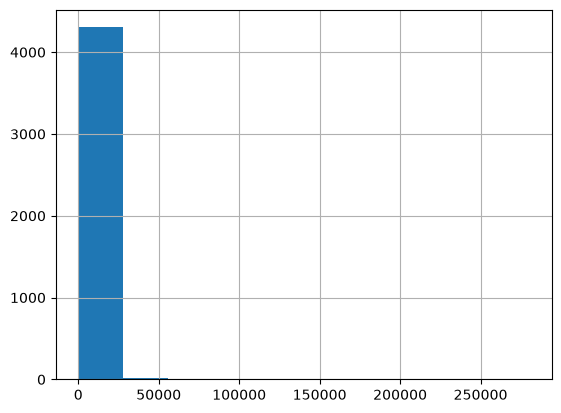

In [250]:
monetary_df=rfm.groupby('CustomerID',as_index=False)['Sales'].sum()
monetary_df.rename(columns={'Sales':'MonetaryValue'},inplace=True)
monetary_df['MonetaryValue'].hist()
monetary_df.describe()

In [251]:
monetary_df['MonetaryValue'].quantile(0.99)

np.float64(19780.487800000003)

<Axes: >

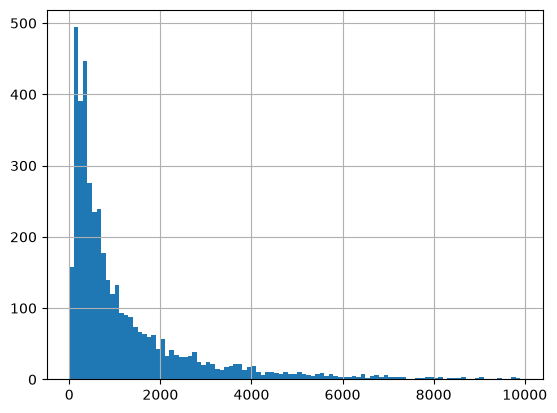

In [252]:
monetary_df['MonetaryValue'].hist(bins=range(0,10000,100))

In [253]:
rfm=frequency_df.copy()
rfm=pd.merge(rfm,recency_df,on='CustomerID')
rfm=pd.merge(rfm,monetary_df,on='CustomerID')
rfm.sort_values('Frequency',ascending=[False])

,CustomerID,Frequency,Last_Purchase_Date,Recency,MonetaryValue
326,12748.0,209,2011-12-09 12:20:00,0.0,33053.19
1879,14911.0,201,2011-12-08 15:54:00,1.0,143711.17
4010,17841.0,124,2011-12-08 12:07:00,1.0,40519.84
562,13089.0,97,2011-12-07 09:02:00,2.0,58762.08
1661,14606.0,93,2011-12-08 19:28:00,1.0,12076.15
...,...,...,...,...,...
4282,18213.0,1,2011-04-17 10:21:00,236.0,232.48
4283,18215.0,1,2011-09-11 16:05:00,89.0,299.34
4325,18269.0,1,2010-12-08 13:53:00,366.0,168.60
4329,18274.0,1,2011-11-09 17:03:00,30.0,175.92


**Customer Segmentation**

                EarliestOrderDate  Age in days
count                        4338  4338.000000
mean   2011-04-30 17:06:50.857538   222.831028
min           2010-12-01 08:26:00     0.000000
25%           2011-01-17 11:13:15   112.000000
50%           2011-04-05 09:52:30   248.000000
75%           2011-08-19 10:11:30   326.000000
max           2011-12-09 12:16:00   373.000000
std                           NaN   117.854570


<Axes: >

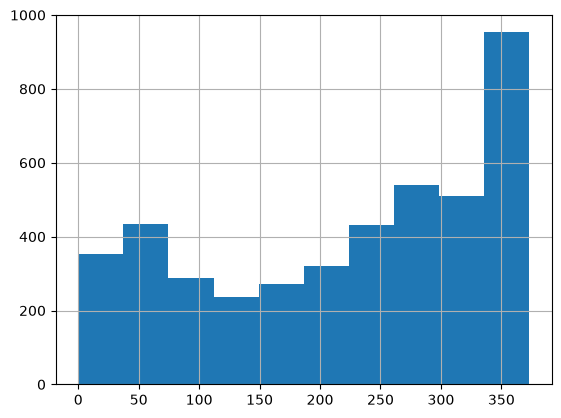

In [254]:
first_order_date=pd.DataFrame(dfnull.groupby(['CustomerID'])['InvoiceDate'].min())
first_order_date.rename(columns={'InvoiceDate':'EarliestOrderDate'},inplace=True)
first_order_date["age"]=(max_date-first_order_date['EarliestOrderDate']).dt.round("D")
first_order_date["Age in days"]=first_order_date["age"]/pd.to_timedelta(1,unit="D")
first_order_date.drop(['age'],axis=1,inplace=True)
print(first_order_date.describe())
first_order_date["Age in days"].hist()

In [255]:
rfm=pd.merge(rfm,first_order_date, on='CustomerID')
rfm['Average time between order in days']=rfm['Age in days']/rfm['Frequency']
rfm['Average monetary value per order']=rfm['MonetaryValue']/rfm['Frequency']
rfm.sort_values('Frequency',ascending=[False])

,CustomerID,Frequency,Last_Purchase_Date,Recency,MonetaryValue,EarliestOrderDate,Age in days,Average time between order in days,Average monetary value per order
326,12748.0,209,2011-12-09 12:20:00,0.0,33053.19,2010-12-01 12:48:00,373.0,1.784689,158.149234
1879,14911.0,201,2011-12-08 15:54:00,1.0,143711.17,2010-12-01 14:05:00,373.0,1.855721,714.980945
4010,17841.0,124,2011-12-08 12:07:00,1.0,40519.84,2010-12-01 14:41:00,373.0,3.008065,326.772903
562,13089.0,97,2011-12-07 09:02:00,2.0,58762.08,2010-12-05 10:27:00,369.0,3.804124,605.794639
1661,14606.0,93,2011-12-08 19:28:00,1.0,12076.15,2010-12-01 16:57:00,373.0,4.010753,129.851075
...,...,...,...,...,...,...,...,...,...
4282,18213.0,1,2011-04-17 10:21:00,236.0,232.48,2011-04-17 10:21:00,236.0,236.000000,232.480000
4283,18215.0,1,2011-09-11 16:05:00,89.0,299.34,2011-09-11 16:05:00,89.0,89.000000,299.340000
4325,18269.0,1,2010-12-08 13:53:00,366.0,168.60,2010-12-08 13:53:00,366.0,366.000000,168.600000
4329,18274.0,1,2011-11-09 17:03:00,30.0,175.92,2011-11-09 17:03:00,30.0,30.000000,175.920000


In [264]:
rfm['R quartile score']=pd.qcut(rfm['Recency'], 4, labels=False)
rfm['R quartile score']=rfm['R quartile score'].replace([0,1,2,3],[4,3,2,1])
rfm['F quartile score']=pd.qcut(rfm['Frequency'].rank(method='first'), 4, labels=False)
rfm['F quartile score']=rfm['F quartile score'].replace([0,1,2,3],[1,2,3,4])
rfm['M quartile score']=pd.qcut(rfm['MonetaryValue'], 4, labels=False)
rfm['M quartile score']=rfm['M quartile score'].replace([0,1,2,3],[1,2,3,4])
rfm['Age quartile score']=pd.qcut(rfm['Age in days'], 4, labels=False)
rfm['Age quartile score']=rfm['Age quartile score'].replace([0,1,2,3],[1,2,3,4])
rfm.sort_values('Recency',ascending=False)

,CustomerID,Frequency,Last_Purchase_Date,Recency,MonetaryValue,EarliestOrderDate,Age in days,Average time between order in days,Average monetary value per order,R quartile score,F quartile score,M quartile score,Age quartile score,K Means Automated Customer Segmentation
355,12791.0,1,2010-12-01 11:27:00,373.0,192.60,2010-12-01 11:27:00,373.0,373.000000,192.600000,1,1,1,4,2
3867,17643.0,1,2010-12-01 14:38:00,373.0,101.55,2010-12-01 14:38:00,373.0,373.000000,101.550000,1,2,1,4,2
1392,14237.0,1,2010-12-01 13:20:00,373.0,161.00,2010-12-01 13:20:00,373.0,373.000000,161.000000,1,1,1,4,2
2067,15165.0,1,2010-12-01 14:03:00,373.0,487.75,2010-12-01 14:03:00,373.0,373.000000,487.750000,1,1,2,4,2
4180,18074.0,1,2010-12-01 09:53:00,373.0,489.60,2010-12-01 09:53:00,373.0,373.000000,489.600000,1,2,2,4,2
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1058,13777.0,33,2011-12-09 12:25:00,0.0,25977.16,2010-12-01 16:01:00,373.0,11.303030,787.186667,4,4,4,4,0
550,13069.0,24,2011-12-09 08:39:00,0.0,4431.44,2010-12-05 11:02:00,369.0,15.375000,184.643333,4,4,4,4,0
3413,17001.0,11,2011-12-09 09:38:00,0.0,3989.57,2010-12-16 09:35:00,358.0,32.545455,362.688182,4,4,4,4,0
71,12433.0,7,2011-12-09 10:02:00,0.0,13375.87,2010-12-01 13:24:00,373.0,53.285714,1910.838571,4,4,4,4,0


**High Value Customers**= Customers who buy often at high value and have bought recently(R=F=M=4)
**Loyal Customers**= Customers who buy regularly even if the value isn’t very large(R= 1-3,F=4, M=1-3)
**Occasional Customers**= Customers who buy often at high value and have bought recently(R=3-4,F=3,M=1-4)
**Inactive Customers**= Customers who haven't bought for a long time and have likely left(R=1,F=1-2,M=1-4)

In [266]:
def create_new_column(row):
    if row['R quartile score'] == 4 and row['F quartile score'] == 4 and row['M quartile score'] == 4 :
        return "High Value Customer"        
    elif row['R quartile score'] < 4 and row['F quartile score'] == 4 and row['M quartile score'] < 4 :
        return "Loyal Customers"
    elif row['R quartile score'] >2 and row['M quartile score'] >1 and row['F quartile score']==3:
        return "Occasional Customers"
    elif row['R quartile score'] < 3 and row['M quartile score'] >=1 and (row['Age quartile score'] ==3 or row['Age quartile score'] ==4):
        return "Inactive Customers"
    else:
        return "Other"

rfm['Manual Customer Segmentation'] = rfm.apply(lambda x: create_new_column(x), axis=1)

In [269]:
rfm['Manual Customer Segmentation'].value_counts()

Manual Customer Segmentation
Other                   2078
Inactive Customers      1048
Occasional Customers     574
High Value Customer      482
Loyal Customers          156
Name: count, dtype: int64

**Customer Segmentation through K means**

In [270]:
from sklearn.preprocessing import StandardScaler

In [271]:
scaler=StandardScaler()
RFM_Scaled = scaler.fit_transform(rfm[["Recency","Frequency","MonetaryValue"]])

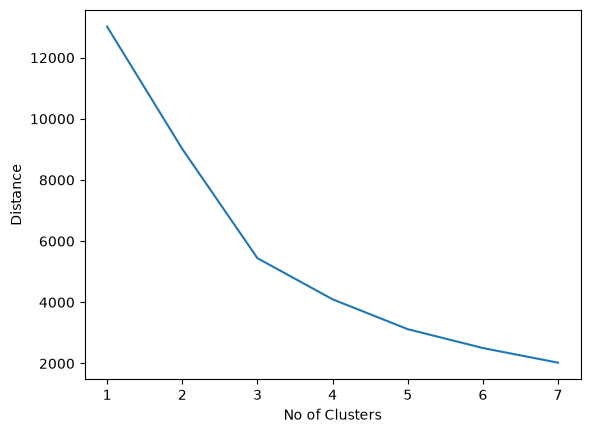

In [272]:
from sklearn.cluster import KMeans
import matplotlib.pyplot as plt
import matplotlib.style as style

range_n_clusters = [1, 2, 3, 4, 5, 6, 7]
avg_distance=[]
for n in range_n_clusters:
    model = KMeans(n_clusters=n,n_init=10, random_state=42).fit(RFM_Scaled)
    avg_distance.append(model.inertia_)

plt.plot(range_n_clusters, avg_distance)
plt.xlabel("No of Clusters")
plt.ylabel("Distance")
plt.show()

In [273]:
model = KMeans(n_clusters=3,n_init=10, random_state=42).fit(RFM_Scaled)
model.labels_
rfm["K Means Automated Customer Segmentation"]=model.labels_
rfm["K Means Automated Customer Segmentation"].value_counts()

K Means Automated Customer Segmentation
0    3225
2    1087
1      26
Name: count, dtype: int64

In [279]:
rfm[(rfm["K Means Automated Customer Segmentation"]==0)].describe()

,CustomerID,Frequency,Last_Purchase_Date,Recency,MonetaryValue,EarliestOrderDate,Age in days,Average time between order in days,Average monetary value per order,R quartile score,F quartile score,M quartile score,Age quartile score,K Means Automated Customer Segmentation
count,3225.000000,3225.000000,3225,3225.000000,3225.000000,3225,3225.000000,3225.000000,3225.000000,3225.000000,3225.000000,3225.000000,3225.000000,3225.0
mean,15283.791938,4.677829,2011-10-29 17:10:42.548837,40.830078,1851.471452,2011-05-19 03:54:29.395348,204.381395,59.215367,384.280888,2.998450,2.758760,2.742946,2.353488,0.0
min,12347.000000,1.000000,2011-06-29 15:42:00,0.000000,6.200000,2010-12-01 08:34:00,0.000000,0.000000,3.450000,1.000000,1.000000,1.000000,1.000000,0.0
25%,13801.000000,2.000000,2011-10-07 10:21:00,12.000000,408.020000,2011-01-20 09:25:00,75.000000,30.000000,192.195000,2.000000,2.000000,2.000000,1.000000,0.0
50%,15288.000000,3.000000,2011-11-09 15:05:00,30.000000,916.980000,2011-05-05 09:53:00,218.000000,52.000000,305.260000,3.000000,3.000000,3.000000,2.000000,0.0
75%,16775.000000,6.000000,2011-11-27 16:08:00,63.000000,2069.770000,2011-09-25 11:33:00,323.000000,79.000000,442.092121,4.000000,4.000000,4.000000,3.000000,0.0
max,18287.000000,55.000000,2011-12-09 12:50:00,163.000000,50491.810000,2011-12-09 12:16:00,373.000000,186.500000,6207.670000,4.000000,4.000000,4.000000,4.000000,0.0
std,1720.301714,5.151196,NaN,35.319663,3055.243666,NaN,125.569120,38.104409,382.180378,0.822488,1.083132,1.080205,1.176568,0.0


In [280]:
rfm[(rfm["K Means Automated Customer Segmentation"]==1)].describe()

,CustomerID,Frequency,Last_Purchase_Date,Recency,MonetaryValue,EarliestOrderDate,Age in days,Average time between order in days,Average monetary value per order,R quartile score,F quartile score,M quartile score,Age quartile score,K Means Automated Customer Segmentation
count,26.000000,26.000000,26,26.000000,26.000000,26,26.000000,26.000000,26.000000,26.000000,26.000000,26.0,26.000000,26.0
mean,15208.615385,66.423077,2011-12-04 01:46:43.846153,5.461538,85826.078077,2010-12-22 20:25:02.307692,351.692308,10.668530,4904.666321,3.923077,3.923077,4.0,3.807692,1.0
min,12415.000000,2.000000,2011-11-01 10:27:00,0.000000,11189.910000,2010-12-01 09:41:00,101.000000,1.784689,129.851075,3.000000,2.000000,4.0,1.000000,1.0
25%,13872.500000,44.250000,2011-12-03 07:55:30,1.000000,37995.347500,2010-12-01 14:14:00,367.000000,4.456515,655.439936,4.000000,4.000000,4.0,4.000000,1.0
50%,14986.000000,53.000000,2011-12-06 22:41:00,2.500000,59697.415000,2010-12-03 12:28:30,371.000000,6.635885,1227.210833,4.000000,4.000000,4.0,4.000000,1.0
75%,16440.000000,82.750000,2011-12-08 15:53:15,6.250000,110673.155000,2010-12-07 14:52:15,373.000000,8.130929,2798.243168,4.000000,4.000000,4.0,4.000000,1.0
max,18102.000000,209.000000,2011-12-09 12:20:00,38.000000,280206.020000,2011-08-30 10:49:00,373.000000,102.500000,84236.250000,4.000000,4.000000,4.0,4.000000,1.0
std,1729.858609,49.129358,NaN,8.659010,70834.064003,NaN,60.853114,19.060571,16255.592525,0.271746,0.392232,0.0,0.693930,0.0


In [281]:
rfm[(rfm["K Means Automated Customer Segmentation"]==2)].describe()

,CustomerID,Frequency,Last_Purchase_Date,Recency,MonetaryValue,EarliestOrderDate,Age in days,Average time between order in days,Average monetary value per order,R quartile score,F quartile score,M quartile score,Age quartile score,K Means Automated Customer Segmentation
count,1087.000000,1087.000000,1087,1087.000000,1087.000000,1087,1087.000000,1087.000000,1087.000000,1087.000000,1087.000000,1087.000000,1087.000000,1087.0
mean,15351.901564,1.581417,2011-04-07 10:04:37.148114,246.122355,629.931399,2011-03-10 01:22:16.007359,274.486661,216.371642,409.310036,1.010120,1.698252,1.743330,2.898804,2.0
min,12346.000000,1.000000,2010-12-01 09:53:00,138.000000,3.750000,2010-12-01 08:26:00,138.000000,10.970588,3.750000,1.000000,1.000000,1.000000,2.000000,2.0
25%,13868.500000,1.000000,2011-02-14 23:16:00,187.000000,170.395000,2011-01-13 11:15:30,221.000000,147.750000,141.355000,1.000000,1.000000,1.000000,2.000000,2.0
50%,15334.000000,1.000000,2011-04-12 13:10:00,241.000000,310.470000,2011-03-08 10:04:00,276.000000,210.000000,229.470000,1.000000,2.000000,2.000000,3.000000,2.0
75%,16807.500000,2.000000,2011-06-05 12:25:30,297.500000,541.920000,2011-05-02 10:38:00,330.000000,284.000000,367.485000,1.000000,2.000000,2.000000,4.000000,2.0
max,18281.000000,34.000000,2011-07-24 16:05:00,373.000000,77183.600000,2011-07-24 16:05:00,373.000000,373.000000,77183.600000,2.000000,4.000000,4.000000,4.000000,2.0
std,1726.605342,1.450390,NaN,67.155510,3006.360287,NaN,67.050169,87.786442,2426.321337,0.100132,0.786059,0.853651,0.778905,0.0


*0-Occasional Customers*
*1-High Value Customers*
*2-Inactive Customers*

Text(0, 0.5, 'MonetaryValue')

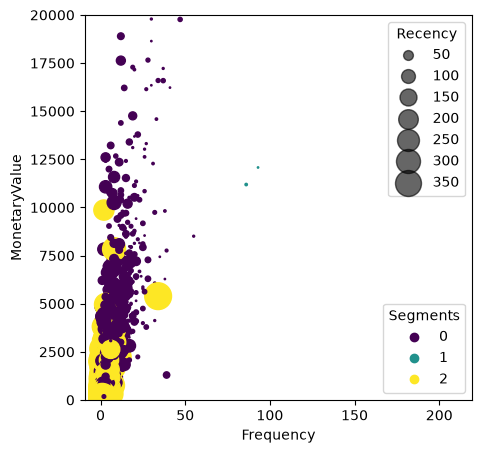

In [275]:
XVariable="Frequency"
YVariable="MonetaryValue"
ZVariable="Recency"
x = rfm[XVariable]
y = rfm[YVariable]
z = rfm[ZVariable]

import numpy as np
from matplotlib import pyplot as plt


fig, ax = plt.subplots(figsize=(5, 5))
scatter = ax.scatter(x, y, c=rfm["K Means Automated Customer Segmentation"], s=z)

# produce a legend with the unique colors from the scatter
legend1 = ax.legend(*scatter.legend_elements(),
                    loc="lower right", title="Segments")
ax.add_artist(legend1)

# produce a legend with a cross-section of sizes from the scatter
handles, labels = scatter.legend_elements(prop="sizes", alpha=0.6)
legend2 = ax.legend(handles, labels, loc="upper right", title=ZVariable)

# Y Axis truncated for better readability...
ax.set_ylim([0, 20000])

plt.xlabel(XVariable)
plt.ylabel(YVariable)

Text(0, 0.5, 'MonetaryValue')

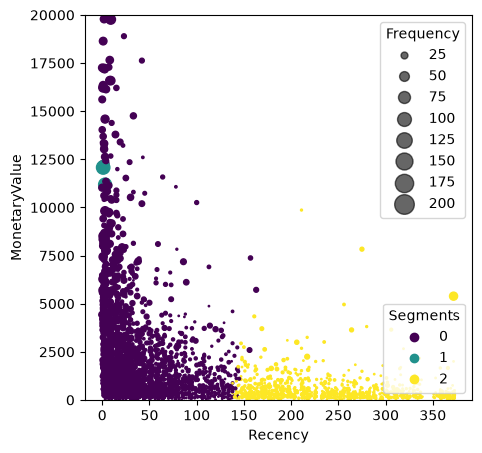

In [276]:
XVariable="Recency"
YVariable="MonetaryValue"
ZVariable="Frequency"
x = rfm[XVariable]
y = rfm[YVariable]
z = rfm[ZVariable]

import numpy as np
from matplotlib import pyplot as plt


fig, ax = plt.subplots(figsize=(5, 5))
scatter = ax.scatter(x, y, c=rfm["K Means Automated Customer Segmentation"], s=z)

# produce a legend with the unique colors from the scatter
legend1 = ax.legend(*scatter.legend_elements(),
                    loc="lower right", title="Segments")
ax.add_artist(legend1)

# produce a legend with a cross-section of sizes from the scatter
handles, labels = scatter.legend_elements(prop="sizes", alpha=0.6)
legend2 = ax.legend(handles, labels, loc="upper right", title=ZVariable)

# Y Axis truncated for better readability...
ax.set_ylim([0, 20000])

plt.xlabel(XVariable)
plt.ylabel(YVariable)

# Predictive Machine Learning

In [295]:
from sklearn.ensemble import RandomForestRegressor
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score, explained_variance_score